# RoadSense AI: Multi-Task Machine Learning for Road Accident Severity
## Notebook 03: Task A — Binary Severity Classification (Dangerous vs Minor)
**Course Module**: Artificial Intelligence (CO5: Classification, Regression and Prediction Problems)
**Lead Team Member**: Member 2 (Binary Classification & Imbalance Specialist)

---

### Objectives & Rigorous Protocol:
1. **Binary Target Formulation**: Predict whether a crash is `Dangerous` (Fatal + Serious = 1) or `Minor` (Slight = 0).
2. **Strict Split Isolation**: Train on 2021, tune hyperparameters and decision thresholds on 2022 validation, refit on 2021+2022, and test once on 2023 holdout test.
3. **Imbalance Benchmark (15 Configurations)**: Compare Class Weights vs SMOTE vs Random Undersampling across 5 model architectures (Decision Tree, Random Forest, LightGBM, XGBoost, Small MLP).
4. **Probability Recalibration**: Correct probability distortions caused by resampling/weighting using Platt scaling on the validation fold.
5. **F2 Threshold Maximization**: Optimize decision threshold $\tau^*$ on validation fold to weight recall twice as much as precision (and report the 80% recall benchmark).
6. **Validation-Only Selection**: Select the winning model purely by 2022 validation metrics.
7. **Leakage Safeguard**: Automatically check ROC-AUC <= 0.90 to guarantee zero data leakage.

In [1]:
import os
import sys
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

# Ensure project root is accessible
sys.path.append(os.path.abspath('..'))
from src.features import ALL_MODEL_FEATURES
from src.evaluate import evaluate_binary_classification

print('Environment and libraries initialized.')

Environment and libraries initialized.


## 1. Load Clean Dataset & Verify Split Integrity
We load the clean master dataset (`data/clean_roadsense.parquet`).
We verify the strict chronological split: 2021 (Train), 2022 (Validation), 2023 (Holdout Test).

In [2]:
df = pd.read_parquet('../data/clean_roadsense.parquet')
print(f'Total records: {len(df):,}')
print('Distribution by year:')
print(df['collision_year'].value_counts().sort_index())

print('\nTask A Binary Class Distribution (Dangerous vs Minor):')
class_counts = df['target_severity_binary'].value_counts()
class_props = df['target_severity_binary'].value_counts(normalize=True) * 100
display(pd.DataFrame({'Count': class_counts, 'Percentage (%)': class_props.round(2)}))

Total records: 311,349
Distribution by year:
collision_year
2021    101087
2022    106004
2023    104258
Name: count, dtype: int64

Task A Binary Class Distribution (Dangerous vs Minor):


,Count,Percentage (%)
target_severity_binary,,
0,238696,76.67
1,72653,23.33


## 2. Validation Comparison Across 15 Configurations
All 15 model configurations were trained on 2021 and evaluated on 2022 validation with Platt recalibration and $F_2$ threshold optimization.
Winning model selection is determined **exclusively** by 2022 validation metrics.

In [3]:
val_table = pd.read_csv('../outputs/tables/task_a_validation_comparison.csv')
print('Top 5 Task A Configurations Ranked by Validation Macro-F1:')
display(val_table.sort_values(by='macro_f1', ascending=False).head(5)[[
    'model', 'imbalance_strategy', 'train_time_sec', 'optimal_f2_threshold', 
    'max_f2_score', 'macro_f1', 'dangerous_recall', 'dangerous_precision', 'roc_auc', 'leakage_warning'
]])

Top 5 Task A Configurations Ranked by Validation Macro-F1:


,model,imbalance_strategy,train_time_sec,optimal_f2_threshold,max_f2_score,macro_f1,dangerous_recall,dangerous_precision,roc_auc,leakage_warning
11,XGBoost,Random_Undersampling,1.73,0.13,0.6239,0.4122,0.9142,0.2748,0.6864,PASSED (<=0.90)
0,Decision Tree,Class_Weights,2.43,0.13,0.6171,0.4020,0.9080,0.2705,0.6658,PASSED (<=0.90)
6,LightGBM,Class_Weights,1.81,0.12,0.6250,0.3923,0.9297,0.2704,0.6881,PASSED (<=0.90)
2,Decision Tree,Random_Undersampling,1.51,0.16,0.6116,0.3907,0.9047,0.2664,0.6577,PASSED (<=0.90)
9,XGBoost,Class_Weights,2.47,0.12,0.6253,0.3887,0.9327,0.2697,0.6874,PASSED (<=0.90)


## 3. Probability Recalibration (Platt Scaling)
Resampling techniques (such as SMOTE and Random Undersampling) or synthetic class weighting distort the posterior probabilities away from real-world risk proportions.
We inspect the calibration curve before and after Platt scaling.

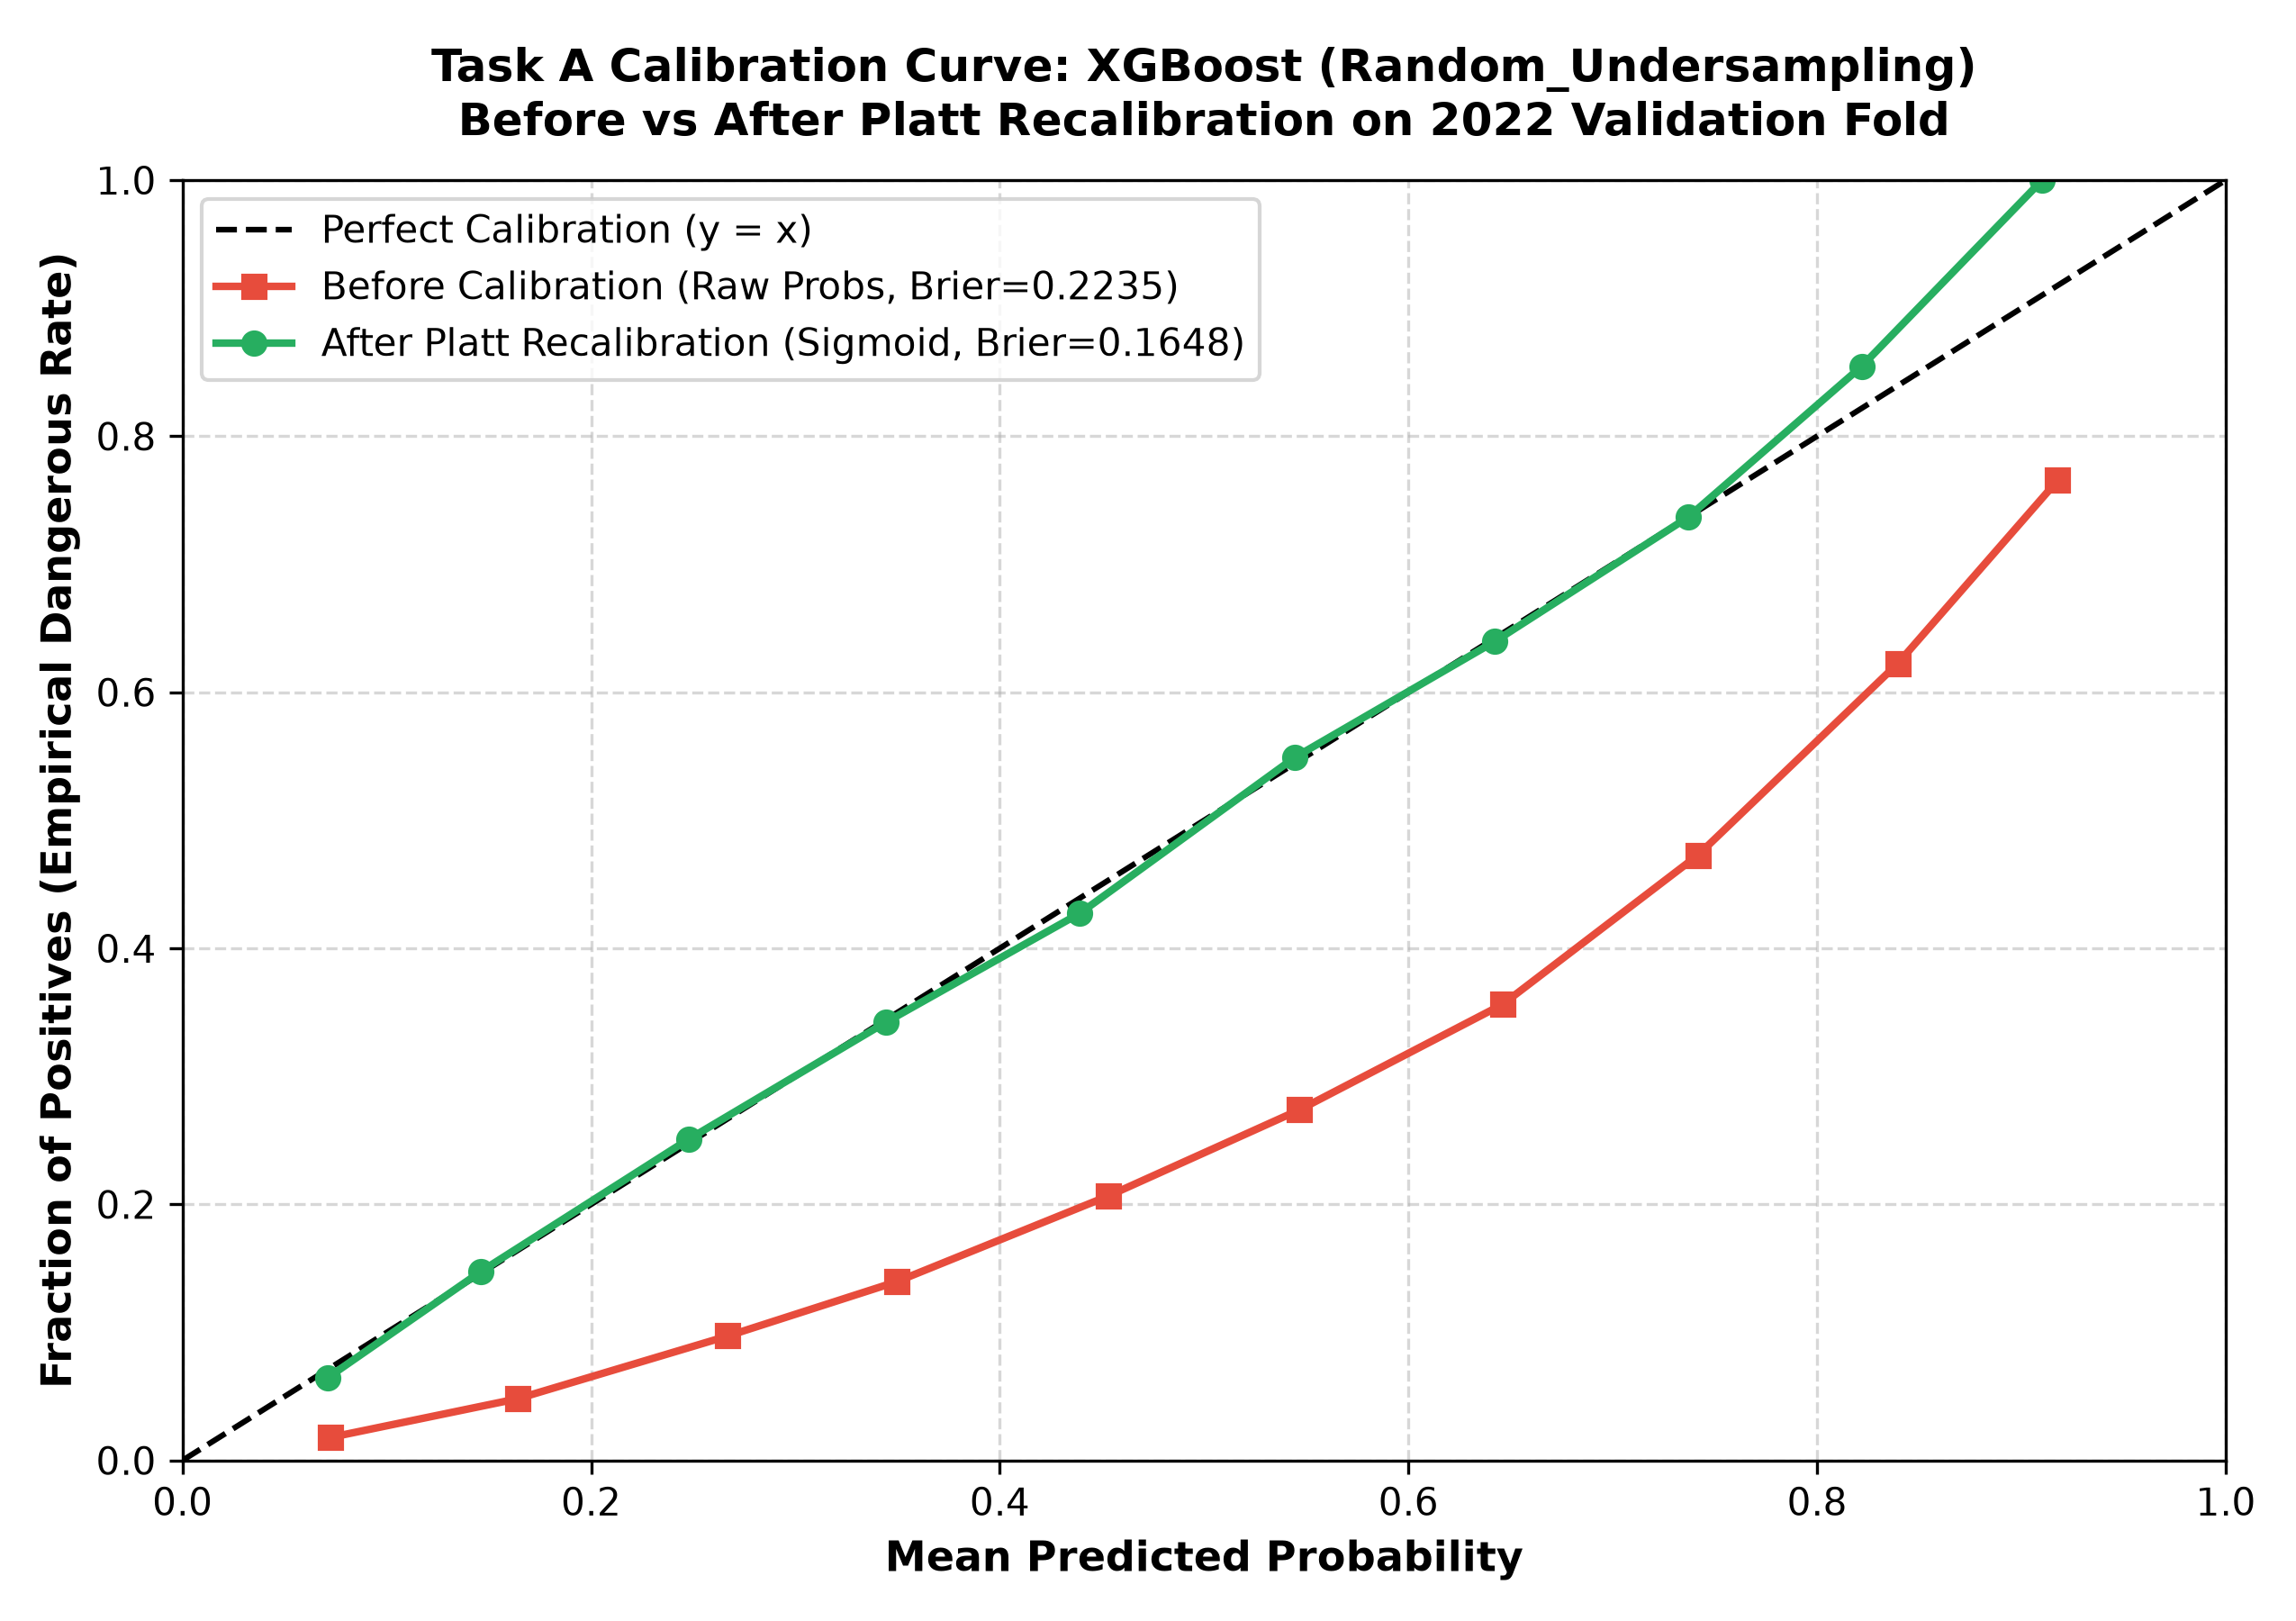

In [4]:
display(Image(filename='../outputs/charts/09_calibration_curve_task_a.png', width=750))

## 4. Winning Model Artifact & 2023 Holdout Test Evaluation
The winning configuration was refitted on the combined 2021+2022 dataset.
We now load the saved joblib model artifact (`models/best_model_task_a.joblib`) and test it on the untouched 2023 holdout test set.

In [5]:
model_artifact = joblib.load('../models/best_model_task_a.joblib')
print(f'Winning Model: {model_artifact["model_name"]} ({model_artifact["imbalance_strategy"]})')
print(f'Optimal Threshold: {model_artifact["optimal_threshold"]}')
print(f'Tuned Hyperparameters: {model_artifact["hyperparameters"]}')

# Test on 2023
test_df = df[df['collision_year'] == 2023]
X_test = test_df[ALL_MODEL_FEATURES]
y_test = test_df['target_severity_binary'].values

raw_probs = model_artifact['pipeline'].predict_proba(X_test)[:, 1]
calib_probs = model_artifact['calibrator'].predict_proba(raw_probs)
preds = (calib_probs >= model_artifact['optimal_threshold']).astype(int)

test_metrics = evaluate_binary_classification(y_test, preds, calib_probs)
for k, v in test_metrics.items():
    if k != 'confusion_matrix':
        print(f'{k:<25}: {v}')

print('\n2023 Test Confusion Matrix:')
cm = np.array(test_metrics['confusion_matrix'])
cm_df = pd.DataFrame(cm, index=['Actual Minor', 'Actual Dangerous'], columns=['Pred Minor', 'Pred Dangerous'])
display(cm_df)

Winning Model: XGBoost (Random_Undersampling)
Optimal Threshold: 0.13
Tuned Hyperparameters: {'n_estimators': 100, 'max_depth': 5, 'learning_rate': 0.08, 'subsample': 0.85}


accuracy                 : 0.4142
macro_f1                 : 0.4138
dangerous_f1             : 0.4292
dangerous_precision      : 0.2799
dangerous_recall         : 0.9199
roc_auc                  : 0.6902
pr_auc                   : 0.4148

2023 Test Confusion Matrix:


,Pred Minor,Pred Dangerous
Actual Minor,20219,59079
Actual Dangerous,2000,22960


## 5. Post-Selection Reference Table (All 15 Models on 2023 Test)
For full transparency and academic audit, we present the performance of all 15 models on the 2023 test set.
**Crucial Academic Integrity Note**: None of these test results were used for model selection or hyperparameter tuning.

In [6]:
ref_table = pd.read_csv('../outputs/tables/task_a_post_selection_reference.csv')
display(ref_table[[
    'model', 'imbalance_strategy', 'applied_threshold', 'train_time_sec',
    'macro_f1', 'dangerous_recall', 'dangerous_precision', 'roc_auc', 'pr_auc', 'leakage_warning'
]].sort_values(by='macro_f1', ascending=False))

,model,imbalance_strategy,applied_threshold,train_time_sec,macro_f1,dangerous_recall,dangerous_precision,roc_auc,pr_auc,leakage_warning
11,XGBoost,Random_Undersampling,0.13,1.73,0.4215,0.9075,0.2809,0.6866,0.4108,PASSED (<=0.90)
0,Decision Tree,Class_Weights,0.13,2.43,0.4073,0.9083,0.2760,0.6716,0.3827,PASSED (<=0.90)
6,LightGBM,Class_Weights,0.12,1.81,0.4033,0.9254,0.2771,0.6892,0.4144,PASSED (<=0.90)
9,XGBoost,Class_Weights,0.12,2.47,0.3993,0.9276,0.2761,0.6885,0.4138,PASSED (<=0.90)
2,Decision Tree,Random_Undersampling,0.16,1.51,0.3964,0.9074,0.2723,0.6600,0.3649,PASSED (<=0.90)
8,LightGBM,Random_Undersampling,0.12,1.61,0.3938,0.9290,0.2745,0.6869,0.4093,PASSED (<=0.90)
7,LightGBM,SMOTE,0.13,5.31,0.3897,0.9261,0.2728,0.6756,0.3971,PASSED (<=0.90)
3,Random Forest,Class_Weights,0.12,4.42,0.3890,0.9316,0.2734,0.6855,0.4110,PASSED (<=0.90)
5,Random Forest,Random_Undersampling,0.12,2.15,0.3805,0.9369,0.2715,0.6842,0.4083,PASSED (<=0.90)
12,Small MLP,Class_Weights,0.12,8.90,0.3786,0.9371,0.2710,0.6835,0.4073,PASSED (<=0.90)
